# LFCC + temporal Swin Transformer on ECGData — reproducible walkthrough

This notebook walks through every stage of the completed `ecgdata_lfcc_small_swin_v1`
experiment and **reproduces its reported results from the saved artifacts**:

1. Environment and frozen protocol
2. Raw `ECGData.mat` → the exact 1,620 corrected baseline windows (hash-checked)
3. Patient-separated five-fold split
4. LFCC feature extraction, step by step, then the full cache rebuilt and compared
5. Fit-only normalization
6. The temporal Swin architecture (shapes, shifted windows, masking)
7. The training procedure — **shown, not executed**
8. Reloading all 15 saved Swin checkpoints and 5 logistic controls; CPU inference vs saved predictions
9. Window and patient-vote metrics, per seed and mean
10. Paired patient-cluster bootstrap (2,000 draws, seed 20260925)
11. Confusion matrices, per-class recall, training curves
12. Summary and limitations

**No model is trained here.** The notebook never calls `run_training`/`fit_swin`/`fit_control`,
never constructs an optimizer, and never writes into `results/` or `features/`. Every
model weight comes from `results/ecgdata_lfcc_swin_v1/` (completed 2026-09-30 UTC on an RTX 5070).
Inference runs on CPU in float32 with one thread.

Reference documents: [results.md](reports/ecgdata_lfcc_swin_v1/results.md),
[protocol](ecgdata_protocol.json), [execution guide](reports/ecgdata_gpu_execution_2026-09-29.md).

**Requirements:** `ECGData.mat` at the repository root, the corrected baseline in
`results/patient_vmd_wst_vqc/`, the LFCC cache `attention method/features/ecgdata_lfcc_v1/`,
and the completed run `attention method/results/ecgdata_lfcc_swin_v1/`. The binaries are gitignored,
so a fresh clone does not contain them. Run with `/home/jaydenlee/venvs/test-ecg-training/bin/python`
(kernel `python3` of that venv); PyTorch 2.7.1+cu128 is loaded from `attention method/.venv/torch-cu128`.

## 1. Environment, paths and reproducibility settings

In [1]:
import os, sys, json, hashlib, platform, time
from pathlib import Path

# Locate 'attention method/' whether the kernel starts there or at the repository root.
here = Path.cwd().resolve()
ROOT = next(p for p in (here, here / 'attention method', here.parent) if (p / 'attention_ecg').is_dir())
REPO = ROOT.parent
TORCH_TARGET = ROOT / '.venv/torch-cu128'
for p in (str(TORCH_TARGET), str(ROOT), str(REPO)):
    if p not in sys.path:
        sys.path.insert(0, p)

# Same numerical settings as the saved run (one CPU thread, float32, deterministic).
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('MPLCONFIGDIR', str(Path(os.environ.get('TMPDIR', '/tmp')) / 'ecg-attention-mpl'))

import numpy as np
import scipy, sklearn, pandas as pd
import matplotlib.pyplot as plt
import torch

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
DEVICE = 'cpu'   # inference only; the GPU is never touched here

RUN = ROOT / 'results/ecgdata_lfcc_swin_v1'
CACHE = ROOT / 'features/ecgdata_lfcc_v1'
REPORTS = ROOT / 'reports/ecgdata_lfcc_swin_v1'
MAT = REPO / 'ECGData.mat'
for path in (RUN, CACHE, MAT, REPO / 'results/patient_vmd_wst_vqc'):
    assert path.exists(), f'Missing required artifact: {path}'

pd.set_option('display.precision', 4)
print('attention method:', ROOT)
print(dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
           sklearn=sklearn.__version__, pandas=pd.__version__, torch=torch.__version__))

attention method: /mnt/d/Projects/test-ecg-training/attention method
{'python': '3.12.3', 'numpy': '2.5.2', 'scipy': '1.18.1', 'sklearn': '1.9.0', 'pandas': '3.0.5', 'torch': '2.7.1+cu128'}


In [2]:
from attention_ecg.ecgdata import (PROTOCOL, read_json, file_hash, array_hash, matched_windows,
                                   verify_cache, fit_normalizer, normalize)
from attention_ecg.cepstral import CepstralConfig, cepstral_features, filterbank
from attention_ecg.model import CepstralSwin, WindowAttention, SwinBlock, PatchMerging
from attention_ecg.ecgdata_training import (partition, batch_indices, verify_trial, load_checkpoint,
                                            pooled_features)
from attention_ecg.ecgdata_report import (confusion, scores, patient_confusions, collect_predictions,
                                          bootstrap_comparison)

protocol = read_json(PROTOCOL)
CLASSES = protocol['classes']
run_manifest = read_json(RUN / 'manifest.json')
saved_report = read_json(RUN / 'report.json')

# The completed run must have been produced by this exact protocol file.
assert run_manifest['protocol_sha256'] == file_hash(PROTOCOL)
assert run_manifest['protocol'] == protocol
print(json.dumps(protocol, indent=1))
print('\nSaved run environment:', json.dumps(run_manifest['versions']), '|', run_manifest['device_name'])
print('Run status:', read_json(RUN / 'status.json'))

{
 "id": "ecgdata_lfcc_small_swin_v1",
 "classes": [
  "ARR",
  "CHF",
  "NSR"
 ],
 "input": {
  "fs": 128,
  "seg_len": 500,
  "n_per_record": 10,
  "seed": 0,
  "zscore_each_window": true
 },
 "reference": {
  "directory": "results/patient_vmd_wst_vqc",
  "windows_sha256": "3eaffccfb4f7390ea677937bd233285d1a918f0810da527b3634566b952f9af9",
  "subject_map_sha256": "b0dfbd8d0f4c030a4a83eaf9eeff81c1ba1d508b5078eca473fa8502cc86855e",
  "fold_sha256": "1d88466d8e2050de0f05fdf3f51b05bdbdd791da114f5e477ffeb472bcc650f5"
 },
 "cepstral": {
  "fs": 128,
  "frame_samples": 128,
  "hop_samples": 32,
  "n_fft": 256,
  "n_filters": 32,
  "n_ceps": 16,
  "fmin": 0.0,
  "fmax": 64.0,
  "spacing": "linear",
  "power_floor": 1e-12
 },
 "model": {
  "n_leads": 1,
  "n_ceps": 16,
  "num_classes": 3,
  "embed_dim": 16,
  "depths": [
   2,
   2
  ],
  "heads": [
   2,
   4
  ],
  "window_size": 4
 },
 "training": {
  "seeds": [
   0,
   1,
   2
  ],
  "epochs": 40,
  "batch_size": 32,
  "optimizer": "Adam

Source-file hashes recorded at training time are compared with the current files. A mismatch does
not invalidate the saved models, but means the code below is not byte-identical to the code that trained them.

In [3]:
rows = []
for rel, digest in run_manifest['sources'].items():
    rows.append(dict(file=rel, unchanged_since_training=file_hash(ROOT / rel) == digest))
pd.DataFrame(rows)

,file,unchanged_since_training
0,attention_ecg/ecgdata_training.py,True
1,attention_ecg/model.py,True
2,ecgdata.py,True


## 2. Raw ECGData → the exact corrected baseline windows

`ECGData.mat` holds 162 lead rows of 65,536 samples at 128 Hz (96 ARR, 30 CHF, 36 NSR rows),
from 81 recordings and 80 patients (MIT-BIH 201/202 are one patient).
The protocol reuses the windows of the corrected patient-grouped VMD/WST baseline: from each row,
10 non-overlapping 500-sample (3.9 s) windows sampled with seed 0, each z-scored.

`matched_windows` re-segments the raw file, then **requires** the window array hash, subject-map hash,
label/patient/source/row alignment and fold assignment hash to match the frozen baseline exactly.

In [4]:
t0 = time.perf_counter()
windows, arrays = matched_windows(MAT, protocol)
print(f'{time.perf_counter() - t0:.1f} s; windows {windows.shape}, dtype {windows.dtype}')
print('windows sha256:', array_hash(windows))
print('expected      :', protocol['reference']['windows_sha256'])
assert array_hash(windows) == protocol['reference']['windows_sha256']
assert array_hash(arrays['fold']) == protocol['reference']['fold_sha256']
y, patients, folds = arrays['y'], arrays['patients'], arrays['fold']
print('rows', len(np.unique(arrays['row_ids'])), '| patients', len(np.unique(patients)),
      '| window mean/std (first):', windows[0].mean().round(6), windows[0].std().round(6))

1.3 s; windows (1620, 500), dtype float64
windows sha256: 3eaffccfb4f7390ea677937bd233285d1a918f0810da527b3634566b952f9af9
expected      : 3eaffccfb4f7390ea677937bd233285d1a918f0810da527b3634566b952f9af9
rows 162 | patients 80 | window mean/std (first): -0.0 1.0


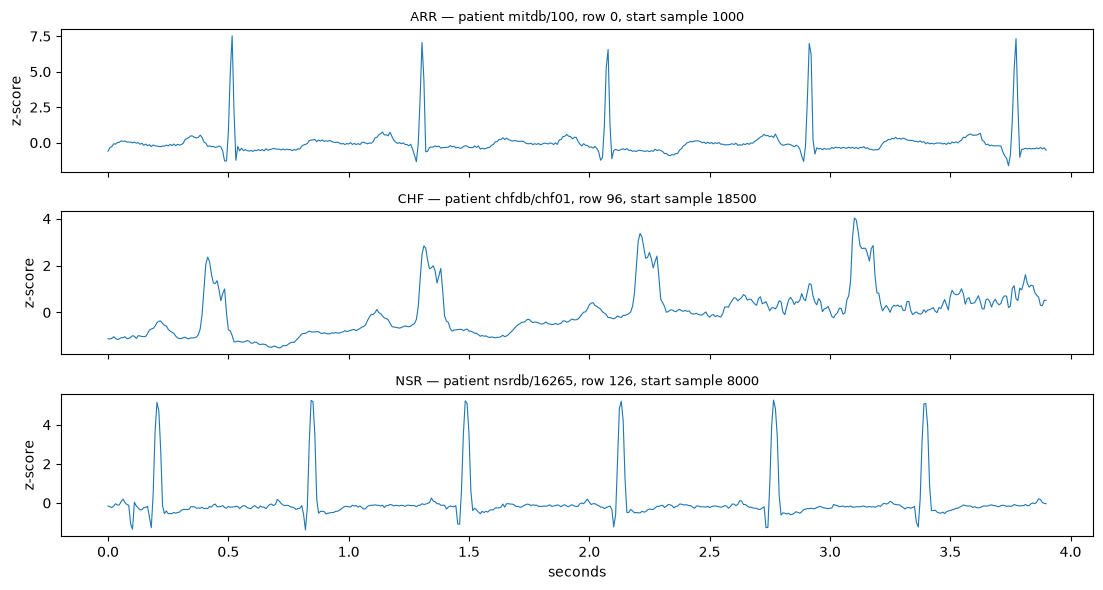

In [5]:
fs = protocol['input']['fs']
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for k, ax in enumerate(axes):
    i = np.flatnonzero(y == k)[0]
    t = np.arange(windows.shape[1]) / fs
    ax.plot(t, windows[i], lw=.8)
    ax.set_title(f'{CLASSES[k]} — patient {patients[i]}, row {arrays["row_ids"][i]}, '
                 f'start sample {arrays["window_start"][i]}', fontsize=9)
    ax.set_ylabel('z-score')
axes[-1].set_xlabel('seconds')
fig.tight_layout()

## 3. Patient-separated five-fold split

All leads, recordings and windows of a patient stay in one outer test fold. Each outer fold trains on
the other four folds. No inner validation set exists in v1: the architecture and 40-epoch budget were
fixed in advance, so outer-fold labels were never used for selection.

In [6]:
split = pd.DataFrame(dict(fold=folds, cls=[CLASSES[k] for k in y], patient=patients))
table = split.pivot_table(index='fold', columns='cls', values='patient', aggfunc='count')
table['windows'] = table.sum(axis=1)
table['patients'] = split.groupby('fold').patient.nunique()
display(table)
display(split.groupby('cls').agg(windows=('patient', 'size'), patients=('patient', 'nunique')))

for fold in range(5):
    tr, te = partition(arrays, fold)   # raises on patient leakage or a missing class
    assert not set(patients[tr]) & set(patients[te])
print('No patient appears in both training and test partitions of any fold.')

cls,ARR,CHF,NSR,windows,patients
fold,,,,,
0,200,60,80,340,16
1,180,60,80,320,16
2,200,60,60,320,16
3,180,60,80,320,16
4,200,60,60,320,16


,windows,patients
cls,,
ARR,960,47
CHF,300,15
NSR,360,18


No patient appears in both training and test partitions of any fold.


## 4. LFCC features, step by step

Settings for the 128 Hz ECGData windows (protocol `cepstral`): 128-sample (1 s) periodic-Hann frames,
hop 32 (0.25 s), 256-point FFT, 32 **linearly spaced** triangular unit-sum bands from 0–64 Hz,
natural log with floor 1e-12, orthonormal DCT-II, retain c0–c15. A 500-sample window needs 12
right-reflected samples so frames cover the end, giving **13 frames × 1 lead × 16 cepstra**.

The cell below reimplements each step by hand on one window and checks it against `cepstral_features`.

In [7]:
cfg = CepstralConfig(**protocol['cepstral'])
x = windows[0][:, None].astype(np.float64)              # (samples, leads)
n = len(x)
pad = (-(n - cfg.frame_samples)) % cfg.hop_samples
xp = np.pad(x, ((0, pad), (0, 0)), mode='reflect')
frames = np.lib.stride_tricks.sliding_window_view(xp, cfg.frame_samples, axis=0)[::cfg.hop_samples]
hann = scipy.signal.get_window('hann', cfg.frame_samples, fftbins=True)
spec = np.fft.rfft(frames * hann, n=cfg.n_fft, axis=-1)
psd = np.abs(spec) ** 2 / (cfg.fs * np.sum(hann ** 2))
psd[..., 1:-1] *= 2                                        # one-sided: double non-DC/non-Nyquist bins
bank = filterbank(cfg)                                     # (32 bands, 129 FFT bins)
band_energy = psd @ bank.T
log_energy = np.log(np.maximum(band_energy, cfg.power_floor))
manual = scipy.fft.dct(log_energy, type=2, norm='ortho', axis=-1)[..., :cfg.n_ceps].astype(np.float32)

library, meta = cepstral_features(windows[0][:, None], cfg)
print('right pad', pad, '| frames', frames.shape, '| PSD', psd.shape, '| bands', band_energy.shape,
      '| LFCC', manual.shape)
print('frame centres (s):', np.round(meta['frame_center_seconds'], 3))
assert np.array_equal(manual, library)
print('Manual pipeline equals cepstral_features exactly.')

right pad 12 | frames (13, 1, 128) | PSD (13, 1, 129) | bands (13, 1, 32) | LFCC (13, 1, 16)
frame centres (s): [0.496 0.746 0.996 1.246 1.496 1.746 1.996 2.246 2.496 2.746 2.996 3.246
 3.496]
Manual pipeline equals cepstral_features exactly.


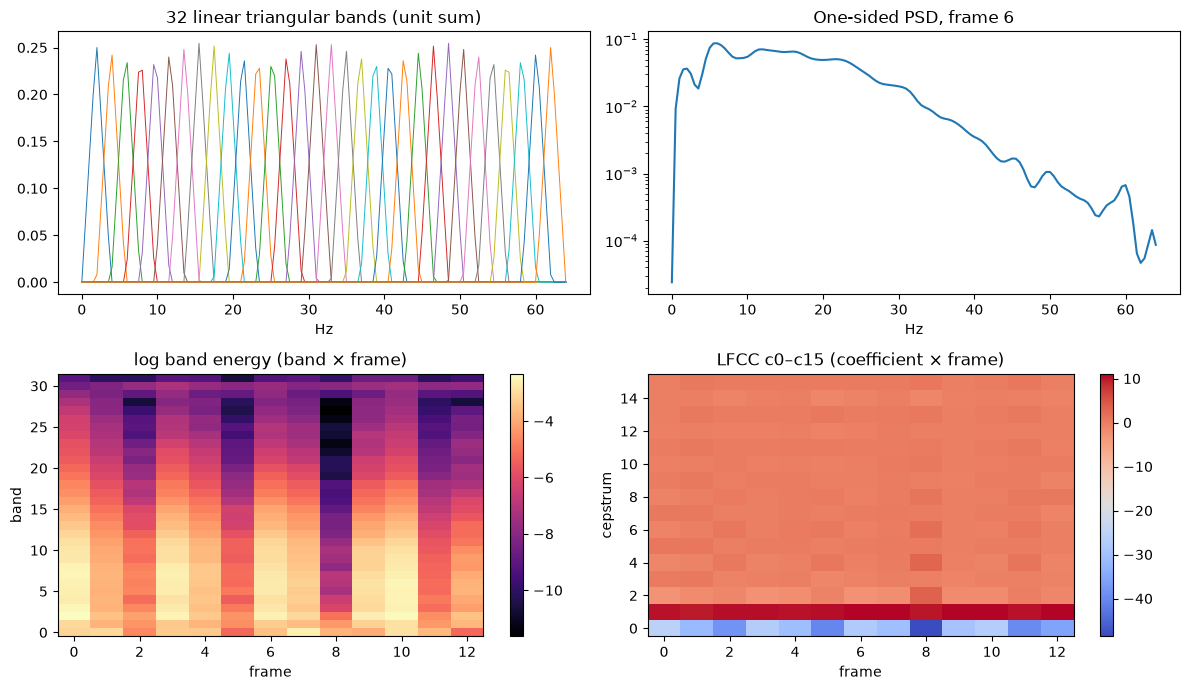

In [8]:
freqs = np.fft.rfftfreq(cfg.n_fft, 1 / cfg.fs)
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].plot(freqs, bank.T, lw=.7); ax[0, 0].set(title='32 linear triangular bands (unit sum)', xlabel='Hz')
ax[0, 1].semilogy(freqs, psd[6, 0]); ax[0, 1].set(title='One-sided PSD, frame 6', xlabel='Hz')
im = ax[1, 0].imshow(log_energy[:, 0].T, aspect='auto', origin='lower', cmap='magma')
ax[1, 0].set(title='log band energy (band × frame)', xlabel='frame', ylabel='band'); fig.colorbar(im, ax=ax[1, 0])
im = ax[1, 1].imshow(library[:, 0].T, aspect='auto', origin='lower', cmap='coolwarm')
ax[1, 1].set(title='LFCC c0–c15 (coefficient × frame)', xlabel='frame', ylabel='cepstrum'); fig.colorbar(im, ax=ax[1, 1])
fig.tight_layout()

### Full LFCC cache: verify, then rebuild in memory and compare

`verify_cache` checks every saved shard and the feature archive against their SHA-256 entries and the
current source hashes. The cache is then recomputed from the windows above (CPU, a few seconds) and must
match bit-for-bit. Nothing is written.

In [9]:
cache_manifest, data = verify_cache(CACHE)
assert run_manifest['cache_completed_sha256'] == file_hash(CACHE / 'completed.json')
print('cache X:', data['X'].shape, data['X'].dtype)

t0 = time.perf_counter()
rebuilt = np.stack([cepstral_features(w[:, None], cfg)[0] for w in windows])
print(f'rebuilt {rebuilt.shape} in {time.perf_counter() - t0:.1f} s')
assert np.array_equal(rebuilt, data['X'])
for key in ('y', 'patients', 'sources', 'row_ids', 'fold', 'window_start'):
    assert np.array_equal(arrays[key], data[key]), key
print('Recomputed LFCC features and metadata equal the saved cache exactly.')

cache X: (1620, 13, 1, 16) float32


rebuilt (1620, 13, 1, 16) in 0.4 s
Recomputed LFCC features and metadata equal the saved cache exactly.


## 5. Fit-only normalization

For each outer fold, a mean and standard deviation per (lead, cepstrum) are computed over the training
windows and all their frames only, then applied to every window. The saved `preprocessing.npz` of each
Swin trial must equal a fresh computation.

In [10]:
rows = []
for fold in range(5):
    tr, te = partition(data, fold)
    mean, scale = fit_normalizer(data['X'], tr)
    for seed in protocol['training']['seeds']:
        with np.load(RUN / f'swin_seed{seed}_fold{fold}' / 'preprocessing.npz') as z:
            assert np.array_equal(z['mean'], mean) and np.array_equal(z['scale'], scale)
            assert np.array_equal(z['train_indices'], tr) and np.array_equal(z['test_indices'], te)
    Xn = normalize(data['X'], mean, scale)
    rows.append(dict(fold=fold, train=len(tr), test=len(te),
                     train_mean_abs=float(np.abs(Xn[tr].mean((0, 1))).max()),
                     train_std=float(Xn[tr].std((0, 1)).mean()),
                     test_mean_abs=float(np.abs(Xn[te].mean((0, 1))).max())))
pd.DataFrame(rows)

,fold,train,test,train_mean_abs,train_std,test_mean_abs
0,0,1280,340,5.8841e-07,1.0,0.2143
1,1,1300,320,3.2429e-07,1.0,0.5705
2,2,1300,320,6.7495e-07,1.0,0.3074
3,3,1300,320,2.7355e-07,1.0,0.1956
4,4,1300,320,4.3994e-07,1.0,0.3037


## 6. The temporal Swin architecture

A 1-D adaptation of Swin, randomly initialized (not a pretrained image Swin):

```
(batch, 13 frames, 1 lead, 16 cepstra)
 -> flatten lead×cepstra -> Linear(16→16) + LayerNorm          frame embedding (one frame = one patch)
 -> stage 1: SwinBlock(dim 16, 2 heads, window 4, shift 0)
             SwinBlock(dim 16, 2 heads, window 4, shift 2)      shifted windows
 -> PatchMerging: concat neighbouring frames -> LayerNorm -> Linear(32→32)   13 -> 7 tokens
 -> stage 2: SwinBlock(dim 32, 4 heads, window 4, shift 0/2)
 -> LayerNorm -> mean over time -> Linear(32→3) logits (ARR, CHF, NSR)
```

Each block: `x + WindowAttention(LN(x))`, then `x + MLP(LN(x))` with a 4× GELU MLP. Attention is restricted
to windows of 4 frames with a learned relative-position bias. Shifted blocks pad on the left instead of
rolling cyclically, and padded positions are masked as keys, so the start and end of the ECG never attend
to each other.

In [11]:
torch.manual_seed(0)
demo = CepstralSwin(**protocol['model']).eval()
n_params = sum(p.numel() for p in demo.parameters())
print(demo)
print('\nparameters:', n_params)
assert n_params == 33607

shapes = []
hooks = [m.register_forward_hook(lambda m, i, o, name=name: shapes.append((name, type(m).__name__, tuple(o.shape))))
         for name, m in demo.named_modules() if isinstance(m, (SwinBlock, PatchMerging)) or name in ('embedding', 'norm', 'head')]
with torch.inference_mode():
    demo(torch.from_numpy(normalize(data['X'][:2], *fit_normalizer(data['X'], np.arange(len(y))))))
for h in hooks:
    h.remove()
pd.DataFrame(shapes, columns=['module', 'type', 'output shape'])

CepstralSwin(
  (embedding): Sequential(
    (0): Linear(in_features=16, out_features=16, bias=True)
    (1): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): SwinBlock(
      (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
      (attn): WindowAttention(
        (qkv): Linear(in_features=16, out_features=48, bias=True)
        (proj): Linear(in_features=16, out_features=16, bias=True)
      )
      (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=16, out_features=64, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=64, out_features=16, bias=True)
      )
    )
    (1): SwinBlock(
      (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
      (attn): WindowAttention(
        (qkv): Linear(in_features=16, out_features=48, bias=True)
        (proj): Linear(in_features=16, out_features=16, bias=True)
      )
      (norm2): L

,module,type,output shape
0,embedding,Sequential,"(2, 13, 16)"
1,stages.0,SwinBlock,"(2, 13, 16)"
2,stages.1,SwinBlock,"(2, 13, 16)"
3,stages.2,PatchMerging,"(2, 7, 32)"
4,stages.3,SwinBlock,"(2, 7, 32)"
5,stages.4,SwinBlock,"(2, 7, 32)"
6,norm,LayerNorm,"(2, 7, 32)"
7,head,Linear,"(2, 3)"


**Shifted-window masking.** For the 13-frame stage-1 sequence, a shifted block (shift 2) pads 2 frames on
the left and 1 on the right, forming 4 windows of 4. The plot marks which keys each query may attend to.

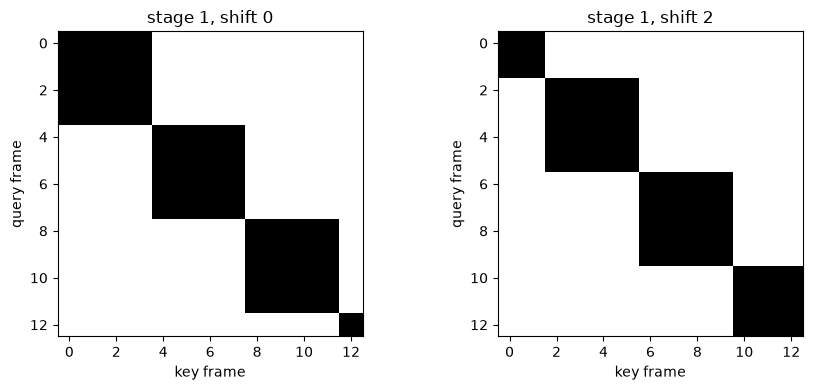

In [12]:
def attention_mask(t, w, shift):
    left = shift if t > w else 0
    right = (-(t + left)) % w
    valid = np.r_[np.zeros(left, bool), np.ones(t, bool), np.zeros(right, bool)]
    total = len(valid)
    mask = np.zeros((total, total), bool)
    for s in range(0, total, w):
        block = slice(s, s + w)
        mask[block, block] = valid[block][None, :]
    keep = valid
    return mask[np.ix_(keep, keep)]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, shift in zip(ax, (0, 2)):
    a.imshow(attention_mask(13, 4, shift), cmap='Greys')
    a.set(title=f'stage 1, shift {shift}', xlabel='key frame', ylabel='query frame')
fig.tight_layout()

## 7. Training procedure — shown, not executed

This is the code path that produced the saved models (`attention_ecg/ecgdata_training.py::fit_swin`).
It is printed for reference only. Settings: AdamW (lr 1e-3, weight decay 0.01), cosine annealing to
1e-4 over 40 epochs, batch 32, class-weighted cross-entropy with weights `n_train / (3 · class_count)`
from the training partition, gradient clipping at norm 1, seeds 0/1/2, shuffle RNG seed + 10000 + epoch,
no early stopping. Training used CUDA with deterministic algorithms and TF32 disabled.

In [13]:
import inspect, attention_ecg.ecgdata_training as training_module
src = inspect.getsource(training_module.fit_swin)
print(src[src.index('    torch.manual_seed'):src.index('    model.eval()')])

    torch.manual_seed(seed)
    if device == 'cuda':
        torch.cuda.manual_seed_all(seed)
    model = CepstralSwin(**protocol['model']).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=settings['lr'], weight_decay=settings['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=settings['epochs'], eta_min=settings['min_lr'])
    counts = np.bincount(data['y'][tr], minlength=3)
    weights = len(tr)/(3*counts)
    criterion = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=device))
    history, first, prior_seconds = [], 0, 0.0
    state = load_checkpoint(folder)
    if state is not None:
        if state['seed'] != seed or state['fold'] != fold:
            raise ValueError('Checkpoint identity mismatch')
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        history, first, prior_seconds 

The saved histories can be checked against this procedure without retraining: every epoch's learning
rate must follow the cosine schedule, the shuffle order is reproducible, and the class weights must match.

In [14]:
s = protocol['training']
rows = []
for fold in range(5):
    tr, _ = partition(data, fold)
    weights = len(tr) / (3 * np.bincount(data['y'][tr], minlength=3))
    for seed in s['seeds']:
        folder = RUN / f'swin_seed{seed}_fold{fold}'
        fit = read_json(folder / 'fit.json')
        hist = read_json(folder / 'history.json')
        np.testing.assert_allclose(fit['class_weights'], weights)
        expected_lr = s['min_lr'] + (s['lr'] - s['min_lr']) * (1 + np.cos(np.pi * np.arange(40) / 40)) / 2
        np.testing.assert_allclose([h['lr'] for h in hist], expected_lr, rtol=1e-12)
        rows.append(dict(seed=seed, fold=fold, epochs=len(hist), first_loss=hist[0]['loss'],
                         final_loss=hist[-1]['loss'], fit_seconds=fit['seconds'],
                         batches_per_epoch=len(batch_indices(len(tr), s['batch_size'], seed, 0, s['shuffle_seed_offset']))))
fits = pd.DataFrame(rows)
print('class weights fold 0:', np.round(len(partition(data, 0)[0]) / (3 * np.bincount(data['y'][partition(data, 0)[0]])), 4))
print(f"sum of Swin fit seconds: {fits.fit_seconds.sum():.3f}")
fits

class weights fold 0: [0.5614 1.7778 1.5238]
sum of Swin fit seconds: 402.211


,seed,fold,epochs,first_loss,final_loss,fit_seconds,batches_per_epoch
0,0,0,40,0.6545,0.0007,25.8129,40
1,1,0,40,0.6535,0.0006,25.8995,40
2,2,0,40,0.6050,0.0005,26.0984,40
3,0,1,40,0.6637,0.0006,26.2279,41
4,1,1,40,0.6198,0.0007,26.4632,41
5,2,1,40,0.6243,0.0005,26.4395,41
6,0,2,40,0.6508,0.0006,26.6050,41
7,1,2,40,0.6235,0.0006,28.1906,41
8,2,2,40,0.5674,0.0004,26.5266,41
9,0,3,40,0.5683,0.0006,26.0880,41


## 8. Reload every saved model and rerun inference on CPU

For each of the 20 trials: verify the completion marker's SHA-256 of every artifact, load the checkpoint
(epoch 40), rebuild the model, normalize with the fold's training statistics, predict the held-out fold
in batches of 32, and compare with the saved CUDA probabilities. Predicted classes must be identical;
probabilities agree to float32 cross-device precision (saved audit: max 1.85e-6).

In [15]:
import joblib

pooled = pooled_features(data['X'])
recomputed = {}          # (arm, seed) -> full out-of-fold predicted classes
probabilities = {}
audit = []
t0 = time.perf_counter()
for fold in range(5):
    tr, te = partition(data, fold)
    for seed in [None] + protocol['training']['seeds']:
        name = f'logistic_fold{fold}' if seed is None else f'swin_seed{seed}_fold{fold}'
        folder = RUN / name
        assert verify_trial(folder), name
        if seed is None:
            model = joblib.load(folder / 'model.joblib')
            prob = model.predict_proba(pooled[te])
            train_pred = model.predict(pooled[tr])
        else:
            state = load_checkpoint(folder)
            assert state['epoch'] == 40 and state['seed'] == seed and state['fold'] == fold
            model = CepstralSwin(**protocol['model']).eval()
            model.load_state_dict(state['model'])
            Xn = normalize(data['X'], *fit_normalizer(data['X'], tr))
            with torch.inference_mode():
                prob = np.concatenate([model(torch.from_numpy(Xn[te[i:i + 32]])).softmax(-1).numpy()
                                       for i in range(0, len(te), 32)])
                train_pred = np.concatenate([model(torch.from_numpy(Xn[tr[i:i + 32]])).argmax(-1).numpy()
                                             for i in range(0, len(tr), 32)])
        with np.load(folder / 'predictions.npz') as saved:
            assert np.array_equal(saved['indices'], te)
            same_class = np.array_equal(prob.argmax(1), saved['pred'])
            max_err = float(np.abs(prob - saved['probabilities']).max())
        key = ('logistic', None) if seed is None else ('swin', seed)
        recomputed.setdefault(key, np.full(len(y), -1))[te] = prob.argmax(1)
        probabilities.setdefault(key, np.full((len(y), 3), np.nan))[te] = prob
        audit.append(dict(trial=name, same_predicted_classes=same_class, max_abs_prob_error=max_err,
                          train_accuracy=float((train_pred == data['y'][tr]).mean()),
                          test_accuracy=float((prob.argmax(1) == data['y'][te]).mean())))
audit = pd.DataFrame(audit)
print(f'{len(audit)} trials in {time.perf_counter() - t0:.1f} s; all classes identical:',
      audit.same_predicted_classes.all(), '| max probability error', audit.max_abs_prob_error.max())
assert audit.same_predicted_classes.all() and audit.max_abs_prob_error.max() < 2e-5
assert all((v >= 0).all() for v in recomputed.values())    # exactly-once out-of-fold coverage
audit

20 trials in 5.5 s; all classes identical: True | max probability error 1.8477439880371094e-06


,trial,same_predicted_classes,max_abs_prob_error,train_accuracy,test_accuracy
0,logistic_fold0,True,0.0000e+00,0.8875,0.7941
1,swin_seed0_fold0,True,1.4305e-06,1.0000,0.8206
2,swin_seed1_fold0,True,1.6093e-06,1.0000,0.8235
3,swin_seed2_fold0,True,1.4305e-06,1.0000,0.8059
4,logistic_fold1,True,0.0000e+00,0.8654,0.8594
5,swin_seed0_fold1,True,1.1325e-06,1.0000,0.8688
6,swin_seed1_fold1,True,1.6391e-06,1.0000,0.8719
7,swin_seed2_fold1,True,1.6689e-06,1.0000,0.8469
8,logistic_fold2,True,0.0000e+00,0.9054,0.6719
9,swin_seed0_fold2,True,1.8477e-06,1.0000,0.7406


## 9. Metrics: window and patient-vote, per seed and mean

Window metrics pool all 1,620 out-of-fold windows. Patient vote takes the majority predicted class
over all of a patient's windows (ties go to the lowest class index). Means average the per-seed
results; they are **not** a seed ensemble. The original VMD + VQC and WST + VQC predictions on the same
windows/folds are loaded from the corrected baseline for comparison, and everything is checked against
the saved `report.json`.

In [16]:
predictions = collect_predictions(RUN, data, protocol)   # read-only: verifies alignment of saved predictions
assert all(np.array_equal(a, b) for a, b in zip(predictions['swin'], [recomputed[('swin', s)] for s in protocol['training']['seeds']]))
assert np.array_equal(predictions['logistic'][0], recomputed[('logistic', None)])

reference = REPO / protocol['reference']['directory'] / 'predictions.npz'
with np.load(reference, allow_pickle=False) as z:
    assert np.array_equal(z['__groups'], data['patients']) and np.array_equal(z['__fold'], data['fold'])
    for arm, key in [('original_vmd_vqc', 'VMD descriptors'), ('original_wst_vqc', 'WST log')]:
        predictions[arm] = [np.array([CLASSES.index(str(l)) for l in z[f'{key} + VQC seed={seed}']])
                            for seed in protocol['training']['seeds']]

results, rows = {}, []
for arm, items in predictions.items():
    per_seed = []
    for i, pred in enumerate(items):
        w, p = patient_confusions(data['y'], pred, data['patients'])
        r = dict(window=scores(w.sum(0)), patient_vote=scores(p.sum(0)))
        per_seed.append(r)
        rows.append(dict(arm=arm, seed='' if arm == 'logistic' else protocol['training']['seeds'][i],
                         window_accuracy=r['window']['accuracy'], window_macro_f1=r['window']['macro_f1'],
                         patient_vote_accuracy=r['patient_vote']['accuracy'],
                         patient_vote_macro_f1=r['patient_vote']['macro_f1']))
    results[arm] = dict(per_seed=per_seed, mean={sc: {m: float(np.mean([r[sc][m] for r in per_seed]))
                        for m in ('accuracy', 'macro_f1', 'balanced_accuracy')} for sc in ('window', 'patient_vote')})

assert results == saved_report['results'], 'Recomputed metrics differ from saved report.json'
print('Recomputed per-seed and mean metrics equal the saved report.json exactly.')
per_seed_table = pd.DataFrame(rows)
display(per_seed_table)

summary = pd.DataFrame({arm: {'window accuracy': r['mean']['window']['accuracy'],
                              'window macro-F1 (primary)': r['mean']['window']['macro_f1'],
                              'patient-vote accuracy': r['mean']['patient_vote']['accuracy'],
                              'patient-vote macro-F1': r['mean']['patient_vote']['macro_f1']}
                        for arm, r in results.items()}).T
summary

Recomputed per-seed and mean metrics equal the saved report.json exactly.


,arm,seed,window_accuracy,window_macro_f1,patient_vote_accuracy,patient_vote_macro_f1
0,swin,0,0.8198,0.7836,0.9250,0.9066
1,swin,1,0.8475,0.8201,0.9625,0.9586
2,swin,2,0.8333,0.7981,0.9375,0.9156
3,logistic,,0.7648,0.7342,0.8750,0.8517
4,original_vmd_vqc,0,0.6778,0.6542,0.8125,0.7911
5,original_vmd_vqc,1,0.6741,0.6387,0.7625,0.7386
6,original_vmd_vqc,2,0.6877,0.6539,0.8250,0.8078
7,original_wst_vqc,0,0.6463,0.6186,0.8000,0.7870
8,original_wst_vqc,1,0.6395,0.6127,0.7500,0.7290
9,original_wst_vqc,2,0.6580,0.6263,0.8000,0.7721


,window accuracy,window macro-F1 (primary),patient-vote accuracy,patient-vote macro-F1
swin,0.8335,0.8006,0.9417,0.9269
logistic,0.7648,0.7342,0.8750,0.8517
original_vmd_vqc,0.6798,0.6489,0.8000,0.7791
original_wst_vqc,0.6479,0.6192,0.7833,0.7627


In [17]:
sw = per_seed_table[per_seed_table.arm == 'swin']
print(f"Swin seed SD: window accuracy {100 * sw.window_accuracy.std(ddof=1):.2f} pp, "
      f"window macro-F1 {sw.window_macro_f1.std(ddof=1):.4f}  (initialization variability only)")

Swin seed SD: window accuracy 1.39 pp, window macro-F1 0.0184  (initialization variability only)


## 10. Paired patient-cluster bootstrap

2,000 resamples of the 80 patients (seed 20260925). Every arm and seed uses the same patient multiplicities
in each draw; seeds are averaged inside a draw. Intervals are conditional on the saved out-of-fold
predictions — they exclude retraining and model-selection uncertainty and are not multiplicity-adjusted.
This takes a few seconds on CPU.

In [18]:
e = protocol['evaluation']
t0 = time.perf_counter()
boot = bootstrap_comparison(data['y'], data['patients'], predictions, e['bootstrap_resamples'], e['bootstrap_seed'])
print(f'{time.perf_counter() - t0:.1f} s; rejected single-class draws: {boot["rejected_single_class_draws"]}')
assert boot == saved_report['bootstrap'], 'Bootstrap differs from saved report.json'
print('Bootstrap intervals equal the saved report.json exactly.')

ci = pd.DataFrame([dict(arm=arm, metric=m, observed=results[arm]['mean'][m.split('_', 1)[0] if m.startswith('window') else 'patient_vote']
                        ['accuracy' if m.endswith('accuracy') else 'macro_f1'], low=b[0], high=b[1])
                   for arm, d in boot['intervals_95'].items() for m, b in d.items()])
display(ci.pivot_table(index='arm', columns='metric', values=['observed', 'low', 'high']).round(4))

diff = pd.DataFrame([dict(comparison=c, metric=m, low=b[0], high=b[1], excludes_zero=b[0] > 0 or b[1] < 0)
                     for c, d in boot['paired_difference_intervals_95'].items() for m, b in d.items()])
diff

1.4 s; rejected single-class draws: 0
Bootstrap intervals equal the saved report.json exactly.


high                                        \
metric           patient_vote_accuracy patient_vote_macro_f1 window_accuracy   
arm                                                                            
logistic                        0.9375                0.9345          0.8150   
original_vmd_vqc                0.8667                0.8488          0.7302   
original_wst_vqc                0.8583                0.8473          0.7071   
swin                            0.9792                0.9706          0.8714   

                                                   low                        \
metric           window_macro_f1 patient_vote_accuracy patient_vote_macro_f1   
arm                                                                            
logistic                  0.7927                0.8000                0.7464   
original_vmd_vqc          0.7059                0.7333                0.6960   
original_wst_vqc          0.6848                0.7042                0.6577   
swin                      0.8432                0.8958                0.8678   

                                                              observed  \
metric           window_accuracy window_macro_f1 patient_vote_accuracy   
arm                                                                      
logistic                  0.7100          0.6577                0.8750   
original_vmd_vqc          0.6258          0.5834                0.8000   
original_wst_vqc          0.5867          0.5376                0.7833   
swin                      0.7933          0.7453                0.9417   

                                                                        
metric           patient_vote_macro_f1 window_accuracy window_macro_f1  
arm                                                                     
logistic                        0.8517          0.7648          0.7342  
original_vmd_vqc                0.7791          0.6798          0.6489  
original_wst_vqc                0.7627          0.6479          0.6192  
swin                            0.9269          0.8335          0.8006

,comparison,metric,low,high,excludes_zero
0,swin_minus_logistic,window_macro_f1,0.0224,0.1143,True
1,swin_minus_logistic,window_accuracy,0.0275,0.1127,True
2,swin_minus_logistic,patient_vote_macro_f1,0.0055,0.1589,True
3,swin_minus_logistic,patient_vote_accuracy,0.0042,0.1333,True
4,swin_minus_original_vmd_vqc,window_macro_f1,0.0899,0.2090,True
5,swin_minus_original_vmd_vqc,window_accuracy,0.0971,0.2054,True
6,swin_minus_original_vmd_vqc,patient_vote_macro_f1,0.0675,0.2323,True
7,swin_minus_original_vmd_vqc,patient_vote_accuracy,0.0707,0.2167,True
8,swin_minus_original_wst_vqc,window_macro_f1,0.1138,0.2532,True
9,swin_minus_original_wst_vqc,window_accuracy,0.1235,0.2506,True


## 11. Confusion matrices, per-class recall and training curves

,ARR window recall,CHF window recall,NSR window recall
swin,0.8882,0.7200,0.7824
logistic,0.7719,0.7067,0.7944
original_vmd_vqc,0.6771,0.6289,0.7296
original_wst_vqc,0.6278,0.5678,0.7685


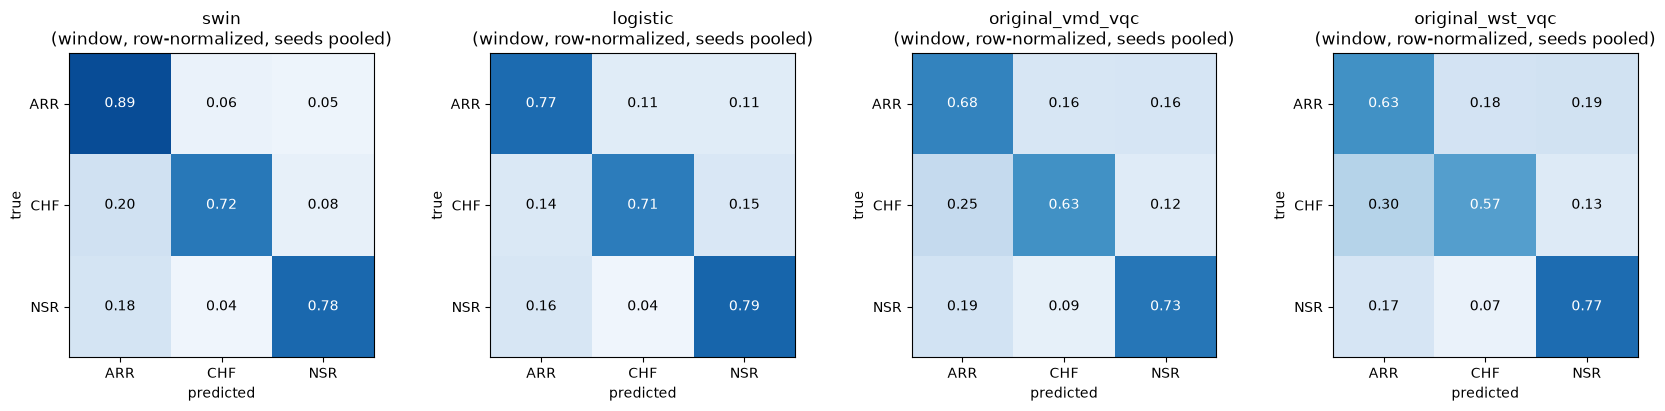

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, arm in zip(axes, results):
    cm = np.sum([np.array(r['window']['confusion_matrix']) for r in results[arm]['per_seed']], axis=0)
    cm = cm / cm.sum(1, keepdims=True)
    ax.imshow(cm, vmin=0, vmax=1, cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > .5 else 'black')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel='predicted', ylabel='true', title=f'{arm}\n(window, row-normalized, seeds pooled)')
fig.tight_layout()

recall = pd.DataFrame({arm: np.mean([r['window']['sensitivity'] for r in results[arm]['per_seed']], axis=0)
                       for arm in results}, index=CLASSES).T
recall.columns = [f'{c} window recall' for c in CLASSES]
recall

Swin training accuracy at epoch 40 (all trials): [1.]
These are training curves only; no held-out curve was recorded, so they do not identify an optimal epoch.


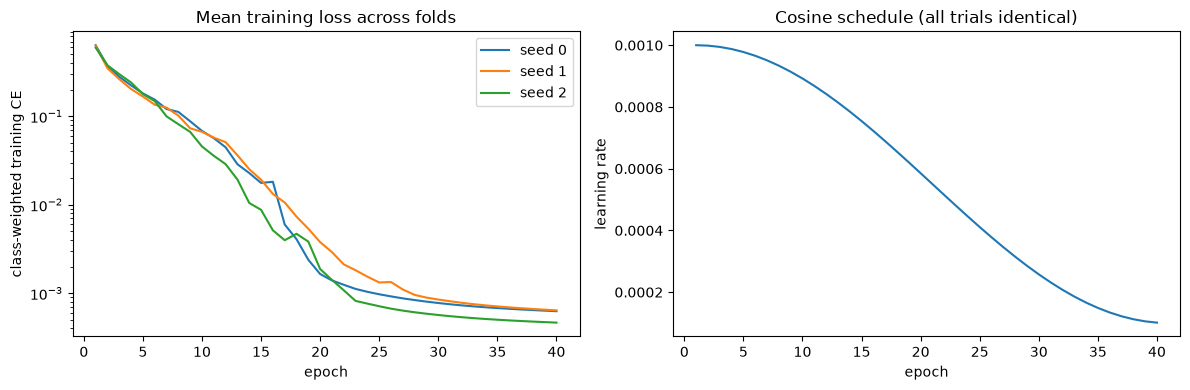

In [20]:
hist = pd.DataFrame([dict(seed=s_, fold=f, **h) for s_ in protocol['training']['seeds'] for f in range(5)
                     for h in read_json(RUN / f'swin_seed{s_}_fold{f}' / 'history.json')])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s_, g in hist.groupby('seed'):
    ax[0].plot(g.groupby('epoch').loss.mean(), label=f'seed {s_}')
ax[0].set(yscale='log', xlabel='epoch', ylabel='class-weighted training CE', title='Mean training loss across folds')
ax[0].legend()
ax[1].plot(hist[(hist.seed == 0) & (hist.fold == 0)].set_index('epoch').lr)
ax[1].set(xlabel='epoch', ylabel='learning rate', title='Cosine schedule (all trials identical)')
fig.tight_layout()
print('Swin training accuracy at epoch 40 (all trials):', audit[audit.trial.str.startswith('swin')].train_accuracy.unique())
print('These are training curves only; no held-out curve was recorded, so they do not identify an optimal epoch.')

## 12. Summary and limitations

If every cell ran without an assertion error, this notebook has, **without any training**:

- regenerated the 1,620 windows from `ECGData.mat` and matched the frozen baseline hashes;
- confirmed patient separation in all five folds;
- reproduced the LFCC features bit-for-bit from the windows;
- reproduced each fold's fit-only normalization;
- reloaded all 15 Swin checkpoints and 5 logistic controls and reproduced their held-out predicted classes on CPU;
- recomputed every per-seed and mean metric and the 2,000-draw paired bootstrap, matching `report.json` exactly.

Expected headline (mean over seeds 0/1/2): Swin window accuracy 83.35%, window macro-F1 0.8006,
patient-vote accuracy 94.17%; pooled-LFCC logistic 76.48% / 0.7342 / 87.50%.

Limitations, as recorded in [results.md](reports/ecgdata_lfcc_swin_v1/results.md):
80 patients only; diagnosis is confounded with source database; the cohort has informed earlier research
decisions, so this is exploratory, not untouched external validation. Every Swin fit reaches 100% training
accuracy, so a generalization gap remains. Pipelines differ in more than one component, so the comparison
does not isolate the contribution of LFCC, attention or model capacity, and does not establish quantum
advantage or VMD-vs-WST superiority. Numerical agreement checks are engineering evidence, not proof of
bug-free software. Intervals are conditional on saved predictions. This is ARR/CHF/NSR classification,
not MI/OMI.

The separate regularization v2 study (`results/ecgdata_lfcc_swin_regularization_v2/`) is not covered here.